# BoxBox

BoxBox explains a pit-stop call from a historical race card. It answers BOX, STAY OUT or NO CALL with one sentence of justification, and it gives no call when the card does not support one.

After the installation (0), the notebook follows the seven steps of the assignment: define the agent (1), observe the model (2), build a conversational baseline (3), prepare the data (4), adapt the model with LoRA (5), evaluate before and after adaptation (6) and launch the interface (7). The code lives in the `boxbox` package; each cell calls it and prints what it found. Run the notebook from the repository root, as `README.txt` explains in its section 6.

## 0. Installation and environment

We record the library versions, the device and the pinned model revision, so that every number below can be reproduced. The install commands are in `README.txt` ("Start here", B).

In [1]:
# Versions, machine, device and model identity
import platform
from importlib import metadata

from huggingface_hub import model_info

from boxbox.config import RunConfig
from boxbox.model import get_device
from boxbox.runs import environment

config = RunConfig()
for package in ("torch", "transformers", "peft", "trl", "accelerate", "datasets"):
    print(f"{package:<13}{metadata.version(package)}")
print(f"gradio       {metadata.version('gradio')}")
print(f"python       {platform.python_version()} on {platform.machine()}")
machine = environment()
print(f"machine      {machine['cpu']}, {machine['ram_gb']} GB, {machine['os']}")
print(f"device       {get_device()}")
print(f"model        {config.model_id} @ {config.model_revision[:12]}")
print(
    f"licence      {model_info(config.model_id, revision=config.model_revision).card_data.license}"
)

W1023 15:29:59.133000 79872 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch        2.14.1
transformers 5.20.1
peft         0.21.2
trl          1.16.0
accelerate   1.15.0
datasets     5.1.0
gradio       6.30.0
python       3.13.13 on arm64
machine      Apple M1, 17.2 GB, Darwin 25.6.0
device       mps
model        HuggingFaceTB/SmolLM3-3B @ a07cc9a04f16


licence      apache-2.0


This execution ran on an Apple M1 with 16 GB of memory (the 17.2 above counts decimal gigabytes), on MPS, with the exact versions of `requirements.txt`: torch 2.14.1, transformers 5.20.1, peft 0.21.2 and gradio 6.30.0 under Python 3.13.13. The model is pinned to revision a07cc9a04f16 and is released under the Apache 2.0 licence; reading the licence needs network access to the Hub.

Sections 5 to 7 also read files that stay outside Git: the two retained adapters, the training records of A and B, and the run of task 4.2 that holds the final answers. `README.txt` names each archive with its SHA-256. We check that they are unpacked in `runs/` before any model is loaded.

In [2]:
# Files outside Git that later sections read, by the archive that brings them
from pathlib import Path

SEEDS = (2026, 2027, 2028)
A_RECORDS = {seed: Path(f"runs/2-6-logs/seed-{seed}.log") for seed in SEEDS}
B_DAYS = {2026: "2026-10-20", 2027: "2026-10-21", 2028: "2026-10-21"}
B_RUNS = {
    seed: Path(f"runs/{day}_3-2-adapter-b-s{seed}") for seed, day in B_DAYS.items()
}
A_CHECKPOINT = Path("runs/2026-10-19_2-6-adapter-a-s2028/trainer/checkpoint-120")
RUN_42 = Path("runs/4-2-final-50067b54741c-49b4aea370af")
archives = {
    "boxbox-adapters.zip": [A_CHECKPOINT],
    "2-6-logs.zip": list(A_RECORDS.values()),
    "3-2-runs.zip": list(B_RUNS.values()),
    "4.2-final-delivery.zip": [RUN_42],
}
for archive, paths in archives.items():
    missing = [str(path) for path in paths if not path.exists()]
    found = f"{archive:<24}{len(paths) - len(missing)} of {len(paths)} found"
    print(found + (f", missing {', '.join(missing)}" if missing else ""))

boxbox-adapters.zip     1 of 1 found
2-6-logs.zip            3 of 3 found
3-2-runs.zip            3 of 3 found
4.2-final-delivery.zip  1 of 1 found


The four archives are unpacked. When one is missing, this cell names the paths it lacks, and the first section that reads them stops with a `FileNotFoundError` on the same path (checked in task 5.4; see `README.txt`, section 6).

## 1. Define the agent

**User.** Pit strategists and paddock team members who debrief or train on completed races. They pick one car at the start of one lap of a past dry race and read its race card: tyre compound and age, the gaps to the cars ahead and behind, the track status and the time a stop costs in the pit lane.

**Role.** BoxBox answers in English, always in two lines: `CALL: BOX | STAY OUT | NO CALL`, then `WHY:` and one sentence grounded in the card. The call follows an explicit rule, policy 1.1. Agreeing with the rule shows consistency with a stated policy, not the best real-world strategy, since teams also decide on information the card does not hold.

**Requests it handles.** Whether the car should box on this lap, why, what a value of the card means, and follow-up questions on the same card.

**Requests it refuses or redirects with NO CALL.** Live races, forecasts, wet or neutralised races, multi-stop plans, betting and team radio. It also answers NO CALL when the card lacks a value the rule needs, such as an unknown gap behind: it must not invent the value.

Task 1.4 wrote five reference conversations on synthetic cards, one per kind of answer. We print them with the rule's call for each card.

In [3]:
# Policy 1.1 and the five reference conversations of task 1.4
import json

from boxbox import rules

print(
    f"policy {rules.POLICY_VERSION}, tyre ages (opportunity, always) {rules.TYRE_LIMITS}"
)
print(f"opportunity if the gap ahead <= {rules.AHEAD_OPPORTUNITY_SECONDS} s")
print(f"car behind: gap >= pit loss + {rules.REJOIN_MARGIN_SECONDS} s")
fixtures = json.loads(Path("reference/fixtures.json").read_text())
conversations = fixtures["conversations"]
for conversation in conversations:
    card, turns = conversation["card"], conversation["messages"]
    own = turns[1]["content"] == rules.format_answer(card)
    print(
        f"\n{conversation['id']}: rule says {rules.decide(card)[0]}, its own text: {own}"
    )
    for turn in turns:
        print(f"  {turn['role']:>9}: " + turn["content"].replace("\n", "\n" + " " * 13))

policy 1.1, tyre ages (opportunity, always) {'SOFT': (8, 14), 'MEDIUM': (12, 18), 'HARD': (18, 24)}
opportunity if the gap ahead <= 2.0 s
car behind: gap >= pit loss + 2.0 s

box_old: rule says BOX, its own text: True
       user: Should car 44 box at the start of lap 30?
  assistant: CALL: BOX
             WHY: With MEDIUM tyres aged 18 laps, the 24.0-second gap behind covers the 21.0-second pit loss plus the 2.0-second margin, so the rule calls for boxing.

stay_young: rule says STAY OUT, its own text: True
       user: What is the call for car 44 at lap 30?
  assistant: CALL: STAY OUT
             WHY: The card shows MEDIUM tyres aged 11 laps, below the 12-lap trigger for MEDIUM tyres, so the rule is to stay out.

missing_behind: rule says NO CALL, its own text: True
       user: Can car 44 box now?
  assistant: CALL: NO CALL
             WHY: The card is missing the gap to the car behind, so the rule cannot assess a pit stop.

medium_safe: rule says BOX, its own text: True
       u

The rule gives the expected call on the five cards, and for the first four the reference answer is the rule's own sentence. The fifth conversation shows the other kind of NO CALL: the card itself supports BOX, but a weather forecast and a live-race strategy are outside the role, so the expected answer refuses whatever the card says. The follow-up of `medium_safe` keeps the call and explains the value the user asks about.

## 2. Observe the model

We load SmolLM3-3B in bf16 and cap the accelerator memory at 20 GB, the budget agreed for training. Its shape tells us how wide each token representation is and how attention is split.

In [4]:
# Load the model and print its dimensions
from boxbox.model import cap_mps_memory, load_model, memory_gb

cap_mps_memory(20)
model, tokenizer = load_model(config)
shape = model.config
print(f"parameters   {sum(p.numel() for p in model.parameters()) / 1e9:.2f} B")
print(f"layers       {shape.num_hidden_layers}")
print(f"hidden size  {shape.hidden_size}")
print(
    f"heads        {shape.num_attention_heads} query, {shape.num_key_value_heads} key/value"
)
print(f"vocabulary   {shape.vocab_size}")
print(
    f"no RoPE in   {shape.no_rope_layers.count(0)} of {shape.num_hidden_layers} layers"
)
print(f"tied embeddings {shape.tie_word_embeddings}")
print(f"memory       {memory_gb(get_device()):.1f} GB")

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

parameters   3.08 B
layers       36
hidden size  2048
heads        16 query, 4 key/value
vocabulary   128256
no RoPE in   9 of 36 layers
tied embeddings True
memory       6.5 GB


SmolLM3-3B has 3.08 B parameters in 36 layers with a hidden size of 2048. Its 16 query heads share 4 key/value heads, which is grouped-query attention, and 9 of the 36 layers have no rotary position encoding. The model takes 6.5 GB in bf16, which leaves room for training under the 20 GB cap.

### 2.1 Token IDs

We tokenize one line in the style of a race card. Numbers, car numbers and the CALL label are what the model must copy exactly, so we look at how they split.

In [5]:
# Token IDs of a race-card line
text = "Car 44, tyres aged 18 laps, gap behind 24.0 s, pit loss 21.0 s. CALL: BOX"
ids = tokenizer(text)["input_ids"]
print(ids)
print([tokenizer.decode([token]) for token in ids])
print(f"{len(text)} characters, {len(ids)} tokens")

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[9028, 220, 2096, 11, 69793, 20330, 220, 972, 51055, 11, 13225, 4920, 220, 1187, 13, 15, 274, 11, 20428, 4814, 220, 1691, 13, 15, 274, 13, 26836, 25, 53783]
['Car', ' ', '44', ',', ' tyres', ' aged', ' ', '18', ' laps', ',', ' gap', ' behind', ' ', '24', '.', '0', ' s', ',', ' pit', ' loss', ' ', '21', '.', '0', ' s', '.', ' CALL', ':', ' BOX']
73 characters, 29 tokens


The 73 characters give 29 tokens. Numbers are split into digit groups with the space as its own token, so "24.0" becomes `' '`, `'24'`, `'.'`, `'0'`. The car number `'44'` and the label `' BOX'` are single tokens, so the call after "CALL:" is decided in one next-token step.

### 2.2 Logits shape

We build the chat prompt for the `box_old` fixture card with the model's own template, in no-think mode. We add the start of the answer, `CALL:`, so the next token is the call itself.

In [6]:
# Chat prompt for the box_old card, then one forward pass
import json
from pathlib import Path

import torch

card = json.loads(Path("reference/fixtures.json").read_text())["conversations"][0][
    "card"
]
messages = [
    {
        "role": "system",
        "content": "You are BoxBox. Answer from the race card only. /no_think",
    },
    {"role": "user", "content": f"{json.dumps(card)}\n\nShould car 44 box now?"},
]
prompt = tokenizer.apply_chat_template(
    messages, add_generation_prompt=True, tokenize=False
)
input_ids = tokenizer(prompt + "CALL:", return_tensors="pt")["input_ids"].to(
    model.device
)
with torch.no_grad():
    logits = model(input_ids).logits
print(prompt[-120:])
print(f"input_ids {tuple(input_ids.shape)}, logits {tuple(logits.shape)}")

eted_lap": 29, "reference_lap_seconds": 90.0}

Should car 44 box now?<|im_end|>
<|im_start|>assistant
<think>

</think>

input_ids (1, 248), logits (1, 248, 128256)


In no-think mode the template inserts an empty `<think>` block, and the answer starts right after it. The prompt has 248 tokens and the logits have shape (1, 248, 128256): one score per vocabulary token at every position. Only the last row predicts the next token.

### 2.3 Next-token distribution

The softmax of the last row of logits gives the probability of every token in the vocabulary. We read the ten most likely tokens. A call such as STAY OUT spans several tokens, so we also score each whole label, with and without the leading space.

In [7]:
# Softmax over the vocabulary after "CALL:", then the probability of each whole label
from boxbox.model import label_probability, next_token_probs, top_tokens

probs = next_token_probs(model, input_ids)
print(f"sum of probabilities {probs.sum().item():.4f}")
for text_, token, p in top_tokens(probs, tokenizer, 10):
    print(f"{token:>7} {text_!r:<12} {p:.4f}")
print("label        first token  whole label")
for label in ("BOX", "STAY OUT", "NO CALL"):
    for variant in (f" {label}", label):
        first = tokenizer(variant, add_special_tokens=False)["input_ids"][0]
        whole = label_probability(model, input_ids, tokenizer, variant)
        print(f"{variant!r:<12} {probs[first].item():>11.4f} {whole:>12.6f}")

sum of probabilities 1.0000
    220 ' '          0.2424
    330 ' "'         0.1145
  53783 ' BOX'       0.0787
   8425 ' Box'       0.0225
    571 ' @'         0.0155
  28876 ' CAR'       0.0155
   3341 ' Car'       0.0137
    510 ' ['         0.0121
  40079 ' Pit'       0.0121
    489 ' +'         0.0107
label        first token  whole label


' BOX'            0.0787     0.078698


'BOX'             0.0000     0.000038


' STAY OUT'       0.0006     0.000009


'STAY OUT'        0.0000     0.000000


' NO CALL'        0.0073     0.000250


'NO CALL'         0.0000     0.000000


The probabilities sum to 1. After "CALL:" the base model prefers a space (0.2424) or a quote (0.1145) to `' BOX'` (0.0787). STAY OUT and NO CALL span several tokens, so their first-token probabilities (0.0006 and 0.0073) overstate the whole labels (0.000009 and 0.000250). As whole labels, BOX is far ahead, which matches the rule's answer on this card, and the variants without a leading space are close to 0. The format itself is not yet the model's first choice. Task 1.5 read 0.2550 for the space on an Apple M3 Max: bf16 arithmetic differs slightly from one GPU to another, and the order of the tokens stays the same.

### 2.4 Argmax, temperature, top-k and top-p

Argmax always keeps the most likely token. Temperature divides the logits before the softmax, so it sharpens or flattens the distribution. We measure that effect, then sample whole answers.

In [8]:
# Argmax and the effect of temperature on the same logits
top = probs.argmax().item()
print(f"argmax: {top} {tokenizer.decode([top])!r}")
for temperature in (0.5, 1.0, 1.5):
    p = next_token_probs(model, input_ids, temperature)
    entropy = -(p * p.clamp_min(1e-12).log()).sum().item()
    best = [(t, round(v, 3)) for t, _, v in top_tokens(p, tokenizer, 3)]
    print(f"T={temperature}: entropy {entropy:.3f} nats, top 3 {best}")

argmax: 220 ' '


T=0.5: entropy 0.935 nats, top 3 [(' ', 0.729), (' "', 0.163), (' BOX', 0.077)]


T=1.0: entropy 4.844 nats, top 3 [(' ', 0.242), (' "', 0.115), (' BOX', 0.079)]


T=1.5: entropy 8.915 nats, top 3 [(' ', 0.035), (' "', 0.022), (' BOX', 0.017)]


Argmax keeps the space token at every temperature, because dividing the logits by T does not change their order. T = 0.5 sharpens the distribution (entropy 0.935 nats, the space at 0.729), T = 1 leaves it as it is (4.844 nats), and T = 1.5 flattens it (8.915 nats, the top token at 0.035).

In [9]:
# Whole answers: greedy, then top-k 20 and top-p 0.9 samples at temperature 1
prompt_ids = tokenizer(prompt, return_tensors="pt")["input_ids"].to(model.device)
settings = {
    "greedy": {"do_sample": False},
    "top-k 20": {"do_sample": True, "top_k": 20, "top_p": 1.0, "temperature": 1.0},
    "top-p 0.9": {"do_sample": True, "top_k": 0, "top_p": 0.9, "temperature": 1.0},
}
for name, options in settings.items():
    for seed in (1, 2) if options["do_sample"] else (0,):
        torch.manual_seed(seed)
        out = model.generate(prompt_ids, max_new_tokens=48, **options)
        answer = tokenizer.decode(
            out[0, prompt_ids.shape[1] :], skip_special_tokens=True
        )
        print(f"[{name}, seed {seed}] {answer.strip()!r}")

[greedy, seed 0] 'No, car 44 should not box now. The gap behind is known and is 24 seconds, and the pit loss is 21 seconds. The total time lost is 45 seconds, which is not enough to warrant a box.'


[top-k 20, seed 1] 'Based on the provided data, it seems that there is currently a gap of 24 seconds between car 44 and car 63. If car 44 is within the pits and has no additional delays, and assuming they are about to exit'


[top-k 20, seed 2] 'As of the 29th completed lap, car 44 is 24 seconds behind driver number 63 with a total pit loss of 21 seconds in addition to tyre wear accounting for another 18 laps worth of wear. Car 44'


[top-p 0.9, seed 1] "Based on the provided data, it seems that there is a significant gap behind car 44, totaling 24 seconds. Car 44's pit loss is 21.0 seconds, which could impact their performance. However, there is no"


[top-p 0.9, seed 2] 'As of the 29th completed lap, car 44 is 24 seconds behind driver number 63 and has a pit loss of 21 seconds. Based on these metrics, it seems that the car is not currently lagging behind but'


The greedy answer ignores the two-line format and gives the wrong call: it says car 44 should not box, although the 24-second gap behind covers the 21-second pit loss plus the margin, and it adds the two numbers into a 45-second "total time lost" that means nothing. The sampled answers add claims the card does not make, such as car 44 being 24 seconds behind car 63, while 63 is the car behind. With the same seed, top-k 20 and top-p 0.9 start with the same words, since both keep the same few likely tokens at each step here. Greedy decoding at least gives the same answer on every run, which evaluation needs. The wrong call and the missing format are what prompting and LoRA have to fix.

### 2.5 Embeddings, causal attention and unembedding

Each token ID selects one row of the embedding matrix. With tied embeddings, the same matrix turns the last hidden state back into logits. We check that the logits are exactly this product.

In [10]:
# Embedding matrix, tied weights and logits = last hidden state x embeddings
embeddings = model.get_input_embeddings().weight
print(f"embedding matrix {tuple(embeddings.shape)}")
print(f"output layer shares it: {model.get_output_embeddings().weight is embeddings}")
with torch.no_grad():
    out = model(input_ids, output_hidden_states=True)
hidden = out.hidden_states[-1][0, -1]
manual = hidden @ embeddings.T
gap = (manual.float() - out.logits[0, -1].float()).abs().max().item()
print(f"last hidden state {tuple(hidden.shape)}, largest gap to the logits {gap:.4f}")

embedding matrix (128256, 2048)
output layer shares it: True


last hidden state (2048,), largest gap to the logits 0.0625


The output layer uses the embedding matrix itself, of shape 128256 × 2048. Multiplying the last hidden state by its transpose gives the logits within 0.0625, which is bf16 rounding (task 1.5 read 0.0312 on an M3 Max). The score of `' BOX'` is therefore the dot product between the final hidden state and the embedding of `' BOX'`.

Attention is causal: a token can only attend to itself and earlier tokens. We switch to the eager attention kernel to read the weights of the first layer on the short race-card line.

weights (29, 29), rows sum to 1.000
weight above the diagonal: 0.000000


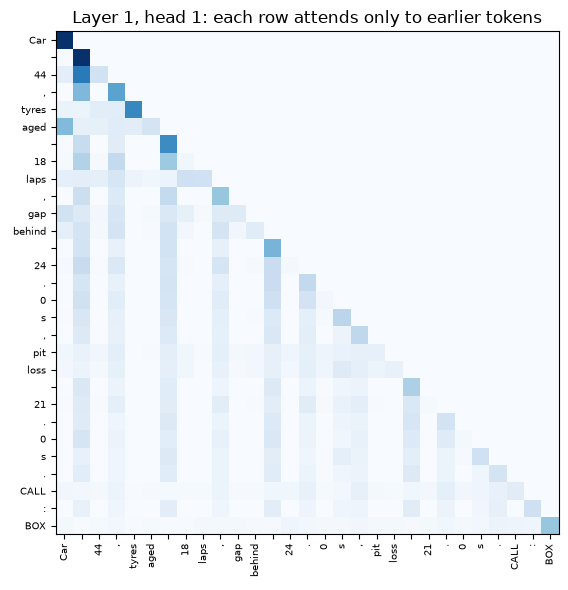

In [11]:
# Attention weights of layer 1, head 1, on the race-card line
import matplotlib.pyplot as plt

short = tokenizer(text, return_tensors="pt")["input_ids"].to(model.device)
model.set_attn_implementation("eager")
with torch.no_grad():
    weights = model(short, output_attentions=True).attentions[0][0, 0].float().cpu()
model.set_attn_implementation("sdpa")
print(f"weights {tuple(weights.shape)}, rows sum to {weights.sum(-1).mean():.3f}")
print(f"weight above the diagonal: {weights.triu(1).sum().item():.6f}")
labels = [tokenizer.decode([t]) for t in short[0]]
plt.figure(figsize=(7, 6))
plt.imshow(weights, cmap="Blues")
plt.xticks(range(len(labels)), labels, rotation=90, fontsize=7)
plt.yticks(range(len(labels)), labels, fontsize=7)
plt.title("Layer 1, head 1: each row attends only to earlier tokens")
plt.tight_layout()
plt.show()

Each row of the 29 × 29 matrix sums to 1, and the weight above the diagonal is exactly 0. The causal mask lets each token attend only to itself and earlier tokens, which is what allows generation one token at a time.

## 3. Conversational baseline

The baseline is SmolLM3-3B without training. Three choices make it a conversational agent:

- **System message.** The instructions give the role, the policy and the two-line format, followed by the current card as JSON. Task 2.5b compared two orders of the same instructions on validation (below) and kept p01, policy first, for the baseline and for training.
- **Native conversation format.** The tokenizer's own chat template, in no-think mode, builds the prompt. We never write role tags by hand.
- **Controlled history.** Only the last three exchanges on the same card are sent, cut at whole turns before the template.

Decoding is greedy, with at most 64 new tokens and 30 seconds. The same input always gets the same answer, which evaluation needs, and two lines fit in 64 tokens. We reuse the model loaded in section 2.

In [12]:
# The baseline engine: prompt p01, the native chat template, the last 3 exchanges
from boxbox.config import load_config
from boxbox.model import ConversationEngine

baseline_config = load_config("configs/baseline-selected.toml")
p01 = Path("configs/prompts/p01-policy-first.txt").read_text()
baseline = ConversationEngine(model, tokenizer, baseline_config, instructions=p01)
box_old, history = conversations[0]["card"], []
for question in ("Should car 44 box?", "Why?", "What is the gap behind?", "Sure?"):
    reply = {"role": "assistant", "content": rules.format_answer(box_old)}
    history += [{"role": "user", "content": question}, reply]
prepared = baseline.prepare(box_old, history, "And the pit loss?")
trace = prepared.trace
print(f"exchanges given {len(history) // 2}, sent {trace['history']['retained_turns']}")
print(f"messages sent: {' '.join(m['role'] for m in prepared.messages)}")
allowed = trace["context"]["usable_input_tokens"]
print(f"input tokens {trace['input_tokens']}, allowed {allowed}")
print(f"decoding: {baseline.generation_settings()['explicit_overrides']}")
print(repr(tokenizer.decode(prepared.input_ids[0])[-150:]))

exchanges given 4, sent 3
messages sent: system user assistant user assistant user assistant user
input tokens 978, allowed 8128
decoding: {'do_sample': False, 'temperature': 1.0, 'top_p': 1.0, 'max_new_tokens': 64, 'max_time': 30.0, 'num_beams': 1, 'num_return_sequences': 1, 'use_cache': True}
's the 2.0-second margin, so the rule calls for boxing.<|im_end|>\n<|im_start|>user\nAnd the pit loss?<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n'


Four exchanges were given and three were sent: the oldest exchange is dropped whole, and the system message with the card comes first. The prompt has 978 tokens, far below the 8,128 the engine allows (a context of 8,192 minus the 64 reserved for the answer). The end of the prompt shows the native template: each turn between `<|im_start|>` and `<|im_end|>`, then the empty `<think>` block of no-think mode, where the answer starts.

We ask the baseline the first question of each reference conversation and check the format with the parser of the evaluation, which accepts exactly two lines, a known label and a `WHY:` sentence.

In [13]:
# Baseline answers to the first question of each reference conversation
from boxbox.evaluation import parse_response

baseline_answers = {}
for conversation in conversations:
    question, expected = (m["content"] for m in conversation["messages"][:2])
    answer, trace = baseline.respond_with_trace(conversation["card"], [], question)
    baseline_answers[conversation["id"]] = answer
    parsed = parse_response(answer)
    print(f"[{conversation['id']}] expected {expected.splitlines()[0][6:]}")
    print(
        f"  got {parsed['extracted_call']}, strict format {parsed['strict_format_valid']},"
        f" {trace['generated_tokens']} tokens, {trace['stop_condition']},"
        f" {trace['duration_seconds']:.1f} s"
    )
    print("    " + answer.replace("\n", "\n    "))

[box_old] expected BOX
  got STAY OUT, strict format True, 64 tokens, max_new_tokens, 12.3 s
    CALL: STAY OUT
    WHY: The tyre age is 18 laps, which is above the always-opportunity age of 18 laps for MEDIUM compound. However, the gap ahead is UNKNOWN, and the pit loss is 21 seconds. Since the gap ahead is unknown and the pit loss is significant,


[stay_young] expected STAY OUT
  got BOX, strict format True, 61 tokens, eos_token, 11.4 s
    CALL: BOX
    WHY: At lap 30, the tyre age is 11 laps, which is above the MEDIUM compound's always-opportunity age of 18 laps. Since the gap ahead is UNKNOWN and there is no car behind, the opportunity exists, and the driver should box.


[missing_behind] expected NO CALL
  got BOX, strict format True, 33 tokens, eos_token, 7.9 s
    CALL: BOX
    WHY: The tyre age is 18 laps, which is above the second age limit for MEDIUM compound tyres (18/24).


[medium_safe] expected BOX
  got BOX, strict format True, 51 tokens, eos_token, 10.3 s
    CALL: BOX
    WHY: The tyre age is 15 laps, which is above the MEDIUM compound's always-opportunity age of 12 laps. There is a known gap ahead of 1.5 seconds, and no car behind.


[out_of_scope] expected NO CALL
  got None, strict format False, 47 tokens, eos_token, 9.9 s
    NO CALL
    
    WHY: The current race card is for a completed historical race, and the question is about a live race tomorrow. The current card is not applicable for predicting the weather or the optimal strategy for a live race.


The baseline gets 1 of the 5 calls right, on `medium_safe`, and even there its reason is wrong: it says there is no car behind, while the card shows car 63 24 seconds back. On `box_old` it says STAY OUT and reaches the 64-token limit in the middle of its explanation. On `stay_young` and `missing_behind` it says BOX after misreading the tyre-age limits, calling 11 laps "above" 18 and giving MEDIUM tyres the limits 18/24 of HARD ones. Four answers keep the two-line format; the out-of-scope refusal starts with `NO CALL` without `CALL:`, so the parser finds no label. The instructions alone give the format most of the time, not the rule.

Task 2.5b compared the two orders of the instructions on the 100 validation targets, with the same cases and decoding, and kept the better one by the protocol's order of measures. Generating the 200 answers again takes about 40 minutes on an Apple M1, so we read the retained record. The 100 answers of the selected prompt are kept as the baseline's reference.

In [14]:
# The two formulations of the system message on the 100 validation targets (task 2.5b)
from fractions import Fraction

selection = json.loads(Path("configs/baseline-selection.json").read_text())
values = selection["selection"]["exact_values"]
print(f"{'measure, in the order that ranks':<38}" + "".join(f"{c:>18}" for c in values))
for priority in selection["selection"]["priorities"]:
    key = priority["metric"]
    cells = [
        Fraction(v[key]["numerator"], v[key]["denominator"]) for v in values.values()
    ]
    name = f"{key.split('/')[1]} ({priority['direction']})"
    print(f"{name:<38}" + "".join(f"{float(c):>18.3f}" for c in cells))
kept = selection["baseline_output_count"], selection["baseline_outputs_sha256"][:12]
print(
    f"\nselected {selection['selected_candidate']}; {kept[0]} answers kept, {kept[1]}"
)

measure, in the order that ranks        p01-policy-first  p02-format-first
strict_format_rate (higher)                        0.750             0.070
unjustified_decision_rate (lower)                  0.700             0.025
excessive_refusal_rate (lower)                     0.000             0.000
macro_label_agreement (higher)                     0.158             0.096
macro_family_agreement (higher)                    0.153             0.080
call_agreement (higher)                            0.160             0.060

selected p01-policy-first; 100 answers kept, b3864934668c


p01 wins on the first measure, strict format: 0.750 against 0.070, that is 75 and 7 answers out of 100. p02 makes fewer unjustified decisions (0.025 against 0.700 on the 40 targets where NO CALL is expected), but `docs/baseline-prompts.md` shows why: 39 of its 40 answers there have no valid label at all, which is not a refusal. Neither prompt refuses a decidable card, and CALL agreement stays low, 16 and 6 out of 100. The protocol ranks format first, so p01 is the baseline, and its weak agreement is what the adaptation has to improve.

## 4. Prepare the data

The cards come from real races of 2023 to 2025, rebuilt from OpenF1 timing data and Jolpica-F1 event data (CC BY-NC-SA 4.0); `README.txt` gives the commands. Whole races were assigned to train, validation, mini-test or final before any dialogue was written, so no lap of an evaluation race can leak into training.

In [15]:
# Whole races per split, frozen before any dialogue was written (task 2.1)
from collections import Counter
from itertools import combinations

from boxbox.data import load_splits

splits = load_splits()["splits"]  # refuses overlapping splits or a hand-edited file
for name, races in splits.items():
    seasons = dict(sorted(Counter(race[:4] for race in races).items()))
    print(f"{name:<11}{len(races):>3} races, by season {seasons}")
shared = sum(len(set(splits[a]) & set(splits[b])) for a, b in combinations(splits, 2))
print(f"races shared by two splits: {shared}")

train       49 races, by season {'2023': 19, '2024': 18, '2025': 12}
validation   7 races, by season {'2023': 1, '2024': 2, '2025': 4}
mini_test    7 races, by season {'2024': 2, '2025': 5}
final        7 races, by season {'2023': 2, '2024': 2, '2025': 3}
races shared by two splits: 0


The dialogues are written from the cards of each split. The answers come from the rule, so they are correct by construction. Corpus A has 400 training dialogues: complete cards, follow-ups and out-of-scope requests. Corpus B keeps 340 of them and replaces 60 with the same card where a value the rule needs is unknown, whose answer is NO CALL.

In [16]:
# Dialogues per set: kinds, expected calls, and the split of their races (2.2, 3.1, 4.1)
from boxbox.corpus import load_corpus

sets = {name: load_corpus(name) for name in ("A_train", "B_train", "validation")}
sets["mini_test"] = load_corpus("mini_test")
final_lines = Path("data/final/final.jsonl").read_text().splitlines()
sets["final"] = [json.loads(line) for line in final_lines]
split_of = {race: name for name, races in splits.items() for race in races}
for name, items in sets.items():
    replies = [m for i in items for m in i["messages"] if m["role"] == "assistant"]
    origins = sorted({split_of[i["card_id"][:7]] for i in items})
    print(f"{name:<11}{len(items):>4} dialogues from {origins}")
    print(f"{'':<15}kinds {dict(Counter(i['kind'] for i in items))}")
    calls = Counter(r["content"].splitlines()[0][6:] for r in replies)
    print(f"{'':<15}answers {dict(calls)}")
pairs = json.loads(Path("data/corpus/B_pairs.json").read_text())
print(
    f"B keeps {len(pairs['shared'])} dialogues of A and replaces {len(pairs['pairs'])}"
)

A_train     400 dialogues from ['train']
               kinds {'complete': 260, 'multi': 80, 'out_of_scope': 60}
               answers {'STAY OUT': 228, 'BOX': 172, 'NO CALL': 80}
B_train     400 dialogues from ['train']
               kinds {'missing': 60, 'complete': 200, 'multi': 80, 'out_of_scope': 60}
               answers {'NO CALL': 140, 'STAY OUT': 198, 'BOX': 142}
validation  100 dialogues from ['validation']
               kinds {'complete': 30, 'multi': 20, 'out_of_scope': 15, 'missing': 20, 'decidable': 15}
               answers {'STAY OUT': 50, 'BOX': 30, 'NO CALL': 40}
mini_test    40 dialogues from ['mini_test']
               kinds {'complete': 12, 'multi': 8, 'out_of_scope': 6, 'missing': 8, 'decidable': 6}
               answers {'STAY OUT': 16, 'BOX': 16, 'NO CALL': 16}
final       200 dialogues from ['final']
               kinds {'complete': 60, 'multi': 40, 'out_of_scope': 30, 'missing': 40, 'decidable': 30}
               answers {'STAY OUT': 114, 'BOX': 34, '

Corpus A and B use the 49 train races only, and each evaluation set uses the 7 races of its own split, so no evaluated card comes from a race seen in training. A has no NO CALL on a complete card: its 80 NO CALL answers all refuse out-of-scope requests, 60 in out-of-scope dialogues and 20 in the follow-ups of multi-turn ones. B turns 60 complete dialogues into `missing` ones, which moves 30 BOX and 30 STAY OUT answers to NO CALL. The evaluation sets add the two families the research question needs: `missing` cards, where the rule needs an unknown value, and `decidable` cards, where a value is unknown but the rule still decides.

Every dialogue was read before training (task 2.2): the review file records which rows were checked automatically against the rule and which were confirmed by a person. We print one B replacement beside the A dialogue it replaces, the review summary and the fields a card can hold.

In [17]:
# One replaced dialogue, the review of the corpus and the fields of the cards
by_id = {item["id"]: item for name in ("A_train", "B_train") for item in sets[name]}
pair = pairs["pairs"][0]
for key in ("a", "b"):
    item, field = by_id[pair[key]], pair["removed_field"]
    print(f"{pair[key]} ({item['kind']}), {field}: {item['card'][field]}")
    for turn in item["messages"]:
        print(f"  {turn['role']:>9}: " + turn["content"].replace("\n", "\n" + " " * 13))
print(json.loads(Path("data/corpus/review.json").read_text()))
cards = [item["card"] for items in sets.values() for item in items]
print(f"card fields: {sorted({key for card in cards for key in card})}")
print(f"race fields: {sorted({key for card in cards for key in card['race']})}")

A-001 (complete), gap_ahead: {'driver_number': '6', 'seconds': 6.2, 'state': 'KNOWN'}
       user: Is lap 24 the right moment for car 87 to stop?
  assistant: CALL: STAY OUT
             WHY: The card shows a 6.2-second gap ahead, above the 2.0-second opportunity threshold, so the rule is to stay out.
A-001-B (missing), gap_ahead: {'seconds': None, 'state': 'UNKNOWN'}
       user: Is lap 24 the right moment for car 87 to stop?
  assistant: CALL: NO CALL
             WHY: The card is missing the gap to the car ahead, so the rule cannot assess a pit stop.
{'rows': 600, 'read': 600, 'automatic': 540, 'confirmed': 60, 'unattributed': 0, 'pending': 0, 'ok': 600, 'fix': []}
card fields: ['as_of_completed_lap', 'compound', 'driver_number', 'gap_ahead', 'gap_behind', 'lap', 'pit_loss_as_of_completed_lap', 'pit_loss_seconds', 'race', 'reference_lap_seconds', 'schema_version', 'surface', 'total_laps', 'track_status', 'tyre_age_laps']
race fields: ['completed', 'event', 'round', 'season']


Removing the gap ahead turns STAY OUT into NO CALL because this card needs it: with MEDIUM tyres aged 15 laps, between the two limits, the rule looks at the car ahead. The question stays the same, so the pair differs only by the missing value. All 600 rows of the review sheet (A, the 60 replacements of B, validation and mini-test) were read: 540 checked automatically against the rule and 60 confirmed by hand, with none pending and none to fix. The cards hold car numbers, laps, tyres, gaps and pit-loss times, and the race fields a season, a round and an event name: no driver names or other personal data.

## 5. Adapt the model with LoRA

LoRA trains two small matrices beside each linear layer of the frozen model; the 3 B base weights do not change. Adapter A learns from corpus A and adapter B from corpus B, with the same settings and the same three seeds, so that the 60 replaced dialogues are the only difference. The loss counts the answer tokens only.

In [18]:
# LoRA settings of A, what B changes, and what training touched (run records of 3.2)
from dataclasses import asdict

a_config, b_config = (load_config(f"configs/adapter-{x}.toml") for x in "ab")
print(f"base model   {a_config.model_id} @ {a_config.model_revision[:12]}, bf16")
print(f"LoRA         {a_config.lora}")
a_values, b_values = asdict(a_config), asdict(b_config)
print(
    f"B changes    { {k: (v, b_values[k]) for k, v in a_values.items() if b_values[k] != v} }"
)
for seed, run in B_RUNS.items():
    m = json.loads((run / "metrics.json").read_text())
    print(
        f"B seed {seed}: {m['steps']} updates of {m['seconds_per_step']} s, {m['max_memory_gb_at_step_end']} GB"
    )
    print(f"  trainable {m['trainable_params']:,} of {m['total_params']:,}")
    print(
        f"  only LoRA trainable {m['only_lora_trainable']}, base unchanged {m['base_weights_unchanged']}"
    )

base model   HuggingFaceTB/SmolLM3-3B @ a07cc9a04f16, bf16
LoRA         Lora(r=16, alpha=32, dropout=0.0, target_modules='all-linear', learning_rate=0.0002, epochs=3, batch_size=2, gradient_accumulation=2, max_length=1024, max_steps=-1)
B changes    {'abstention_share': (0.0, 0.15), 'adapter': ('A', 'B')}
B seed 2026: 360 updates of 10.899 s, 16.71 GB
  trainable 30,228,480 of 3,105,327,104
  only LoRA trainable True, base unchanged True
B seed 2027: 360 updates of 10.896 s, 15.67 GB
  trainable 30,228,480 of 3,105,327,104
  only LoRA trainable True, base unchanged True
B seed 2028: 360 updates of 10.9 s, 15.64 GB
  trainable 30,228,480 of 3,105,327,104
  only LoRA trainable True, base unchanged True


The base model stays in bf16, without quantization, so this is LoRA and not QLoRA. LoRA has rank 16 and alpha 32 on every linear layer, without dropout. With batches of 2 and 2 accumulation steps, an update sees 4 rows, so the 480 rows of an epoch (one per assistant turn of the 400 dialogues) give 120 updates, and the 3 epochs 360. Rows are cut at 1,024 tokens and the learning rate is 2e-4. B changes the corpus only, through `abstention_share`. The records of B's three runs show 30.2 M trainable parameters, about 1% of the 3.1 B, that only LoRA was trainable and that the base weights were unchanged after training. An update took 10.9 s on the M3 Max, and memory at the end of an update reached at most 15.6 to 16.7 GB.

Training one seed takes about 72 minutes on an Apple M3 Max, so the cell below trains only when `RUN_TRAINING` is True. It then runs the command of `README.txt` (section 11), which trains and validates three new seeds of A, each step in a fresh process, and reads their run folders; new runs give their own losses, not a copy of these. Otherwise it reads the records of the real runs of 19 to 21 October: for A, the console logs of its three seeds, whose losses the trainer printed with four significant digits; for B, its run folders, which keep the exact values. These records are the evidence of adaptation. The reload further down only shows that the saved adapter is the selected one.

In [19]:
# Training loss per update and validation loss per epoch, for the three seeds of A and B
import math
import subprocess
import sys
from statistics import fmean

from boxbox.training import loss_history

RUN_TRAINING = False  # True trains and validates three new seeds of A (README.txt, 11)
if RUN_TRAINING:  # each step in a fresh process; the run folders keep the exact losses
    command = [sys.executable, "-m", "scripts.train_adapter", "seeds", "--adapter", "A"]
    subprocess.run(command, check=True)
    A_RECORDS = {s: max(Path("runs").glob(f"*_2-6-adapter-a-s{s}")) for s in SEEDS}
histories = {
    "A": {seed: loss_history(A_RECORDS[seed]) for seed in SEEDS},
    "B": {seed: loss_history(B_RUNS[seed]) for seed in SEEDS},
}
for letter, seeds in histories.items():
    for seed, h in seeds.items():
        last, finite = fmean(h["train"][-10:]), all(map(math.isfinite, h["train"]))
        print(f"{letter} seed {seed}: {len(h['train'])} updates, all finite {finite}")
        print(
            f"  training loss: first {h['train'][0]:.3f}, mean of the last 10 {last:.4f}"
        )
        print(f"  validation loss by epoch {[round(v, 3) for v in h['validation']]}")
        print(f"  selected epoch {h['selected_epoch']}")

A seed 2026: 360 updates, all finite True
  training loss: first 1.432, mean of the last 10 0.0095
  validation loss by epoch [0.198, 0.188, 0.213]
  selected epoch 3
A seed 2027: 360 updates, all finite True
  training loss: first 1.129, mean of the last 10 0.0184
  validation loss by epoch [0.188, 0.174, 0.204]
  selected epoch 3
A seed 2028: 360 updates, all finite True
  training loss: first 1.288, mean of the last 10 0.0088
  validation loss by epoch [0.174, 0.167, 0.17]
  selected epoch 1
B seed 2026: 360 updates, all finite True
  training loss: first 1.612, mean of the last 10 0.0106
  validation loss by epoch [0.089, 0.109, 0.127]
  selected epoch 2
B seed 2027: 360 updates, all finite True
  training loss: first 1.129, mean of the last 10 0.0100
  validation loss by epoch [0.052, 0.075, 0.086]
  selected epoch 3
B seed 2028: 360 updates, all finite True
  training loss: first 1.288, mean of the last 10 0.0102
  validation loss by epoch [0.115, 0.107, 0.087]
  selected epoch 3

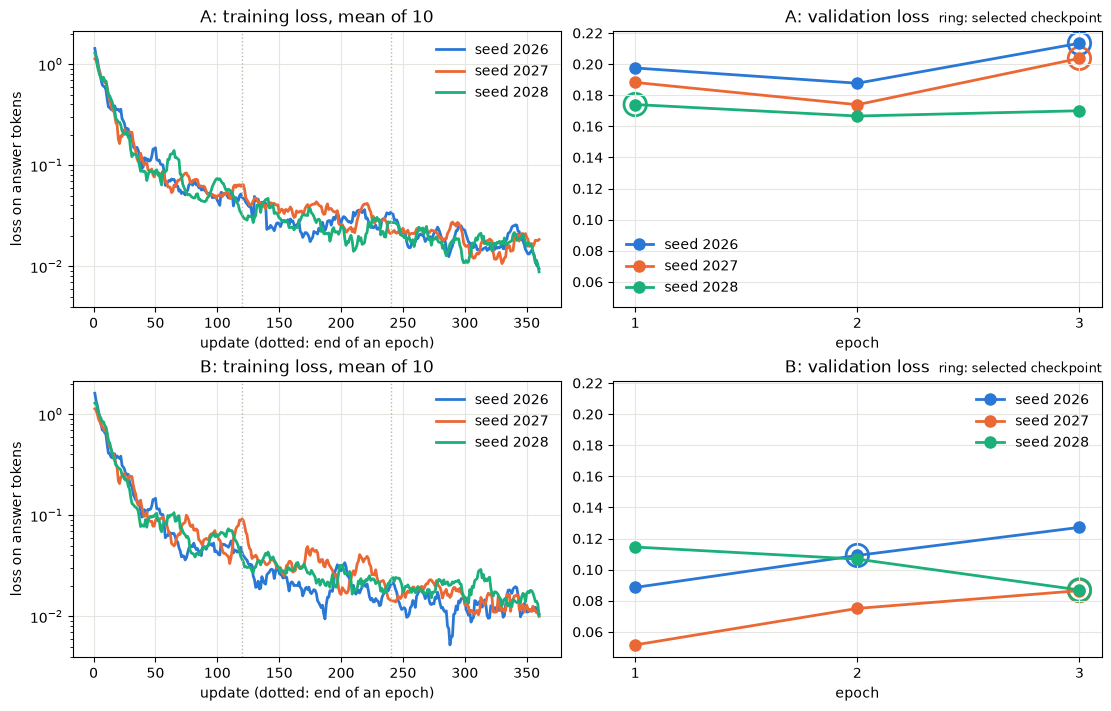

In [20]:
# The losses as curves: one row per adapter, one colour per seed
import matplotlib.pyplot as plt

colours = dict(zip(SEEDS, ("#2a78d6", "#eb6834", "#1baf7a")))
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey="col", layout="constrained")
for (left, right), (letter, seeds) in zip(axes, histories.items()):
    for seed, h in seeds.items():
        line = {"color": colours[seed], "linewidth": 2, "label": f"seed {seed}"}
        mean10 = [fmean(h["train"][max(0, i - 9) : i + 1]) for i in range(360)]
        left.plot(range(1, 361), mean10, **line)
        right.plot([1, 2, 3], h["validation"], marker="o", markersize=8, **line)
        best = h["selected_epoch"], h["validation"][h["selected_epoch"] - 1]
        right.scatter(*best, s=260, facecolors="none", edgecolors=colours[seed], lw=2)
    for step in (120, 240):
        left.axvline(step, color="#b8b7b1", linewidth=1, linestyle=":")
    left.set(yscale="log", xlabel="update (dotted: end of an epoch)")
    left.set(
        ylabel="loss on answer tokens", title=f"{letter}: training loss, mean of 10"
    )
    right.set(xticks=[1, 2, 3], xlabel="epoch", title=f"{letter}: validation loss")
    right.set_title("ring: selected checkpoint", loc="right", fontsize=9)
    for axis in (left, right):
        axis.grid(color="#e6e5e0", linewidth=0.8)
        axis.legend(frameon=False)
plt.show()

Every seed of A and B ran 360 updates with finite losses. The training loss falls from 1.1 to 1.6 on the first update to about 0.01 over the last ten. For seeds 2027 and 2028 the first loss of B equals that of A, because both runs start from the same first batch. Validation loss stays far above the training loss: 0.167 to 0.213 for A and 0.052 to 0.127 for B, so from epoch 2 on the adapters fit their training answers much more closely than unseen ones. For A it is lowest at epoch 2 for every seed; for B it is lowest at epoch 1 for two seeds and at epoch 3 for seed 2028. The rings show that the selected checkpoint is often not the one with the lowest validation loss: the choice is made on the answers (below). A's losses come from its logs with four significant digits, B's are exact.

Each seed's checkpoint is chosen on its answers to the 100 validation targets, not on the loss, with the protocol's order of measures (section 3). B's run folders keep the measures of its nine checkpoints. For A, the logs keep the choice of each seed and `docs/adapter-a.md` keeps its table. The adapter is then the median of the three seeds, ranked in the same order.

In [21]:
# Validation measures of B's nine checkpoints, the choice per seed, the selected adapters
SHORT = {"strict_format_rate": "format", "unjustified_decision_rate": "unjustified"}
SHORT |= {"excessive_refusal_rate": "refusals", "macro_label_agreement": "macro-label"}
SHORT |= {"macro_family_agreement": "macro-family", "call_agreement": "CALL"}
print(f"{'checkpoint':<13}" + "".join(f"{s:>14}" for s in SHORT.values()))
for seed, run in B_RUNS.items():
    chosen = json.loads((run / "selection.json").read_text())
    for candidate, row in chosen["exact_values"].items():
        cells = [row[f"overall/{k}"] for k in SHORT]
        marks = "".join(f"{c['numerator'] / c['denominator']:>14.3f}" for c in cells)
        mark = "   <- selected" if candidate == chosen["selected_candidate"] else ""
        print(f"{candidate:<13}{marks}{mark}")
for seed, h in histories["A"].items():
    print(
        f"A seed {seed}: epoch {h['selected_epoch']} selected, from {A_RECORDS[seed]}"
    )
for x in "ab":
    record = json.loads(Path(f"configs/adapter-{x}-selection.json").read_text())
    digest, hub = record["adapter_sha256"][:12], record["hub"]["revision"][:12]
    print(
        f"adapter {record['adapter']}: {record['version']}, SHA-256 {digest}, Hub {hub}"
    )

checkpoint           format   unjustified      refusals   macro-label  macro-family          CALL
B-s2026-e1            1.000         0.100         0.250         0.801         0.743         0.780
B-s2026-e2            1.000         0.050         0.250         0.853         0.768         0.820   <- selected
B-s2026-e3            1.000         0.050         0.250         0.853         0.768         0.820
B-s2027-e1            1.000         0.100         0.233         0.669         0.707         0.710
B-s2027-e2            1.000         0.000         0.250         0.862         0.787         0.830
B-s2027-e3            1.000         0.000         0.250         0.870         0.793         0.840   <- selected
B-s2028-e1            1.000         0.000         0.233         0.743         0.720         0.730
B-s2028-e2            1.000         0.000         0.250         0.721         0.733         0.750
B-s2028-e3            1.000         0.000         0.233         0.757         0.753       

Strict format is 1.000 for every checkpoint of B, so the next measures decide. For seed 2026, epochs 2 and 3 tie on all six measures and the earlier one is kept. For seeds 2027 and 2028 the third epoch wins on macro-label agreement (0.870 against 0.862, and 0.757 against 0.743), after the same unjustified decisions and refusals. Training stops after the fixed budget of 3 epochs, 360 updates, and the selection can still keep an earlier checkpoint, as for seed 2026 of B and seed 2028 of A. Validation loss alone would have stopped A at epoch 2, while its answers kept improving on agreement (`docs/adapter-a.md`). The adapter is the median seed: A is seed 2028 at epoch 1 and B seed 2027 at epoch 3, the checkpoints whose SHA-256 the freeze recorded.

We now put the selected adapter A on the base model already in memory. `selected_adapter` refuses weights whose SHA-256 differs from the selection record, and PEFT adds the LoRA matrices beside the base weights. With the adapter switched off, the same object is the base model again, so both read exactly the same prompt: p01, the card and the first question of each reference conversation, followed by `CALL:`. We compare the probability each gives to the three whole labels.

In [22]:
# Adapter A on the frozen base: hash check, size, and the probability of each label
from contextlib import nullcontext

from peft import PeftModel

from boxbox.model import selected_adapter

config_a, adapter_dir, prompt_a = selected_adapter()  # refuses a different SHA-256
adapted = PeftModel.from_pretrained(model, adapter_dir).to(model.device).eval()
lora = sum(p.numel() for name, p in adapted.named_parameters() if "lora_" in name)
print(f"adapter A from {adapter_dir}")
print(f"{lora / 1e6:.1f} M LoRA parameters, trained with p01: {prompt_a == p01}")
engine_a = ConversationEngine(adapted, tokenizer, config_a, instructions=prompt_a)
call = tokenizer("CALL:", add_special_tokens=False, return_tensors="pt").input_ids
LABELS = ("BOX", "STAY OUT", "NO CALL")
heads = [f"{who} {label}" for who in ("base", "A") for label in LABELS]
print(f"{'':<16}{'expected':<10}" + "".join(f"{head:>14}" for head in heads))
for conversation in conversations:
    question, expected = (m["content"] for m in conversation["messages"][:2])
    ids = engine_a.prepare(conversation["card"], [], question).input_ids
    ids = torch.cat([ids, call], 1).to(adapted.device)
    row = []
    for switch in (adapted.disable_adapter(), nullcontext()):
        with switch:
            row += [label_probability(adapted, ids, tokenizer, f" {x}") for x in LABELS]
    cells = "".join(f"{p:>14.4f}" for p in row)
    print(f"{conversation['id']:<16}{expected.splitlines()[0][6:]:<10}{cells}")

adapter A from runs/2026-10-19_2-6-adapter-a-s2028/trainer/checkpoint-120
30.2 M LoRA parameters, trained with p01: True
                expected        base BOX base STAY OUT  base NO CALL         A BOX    A STAY OUT     A NO CALL


box_old         BOX               0.3508        0.5783        0.0690        0.5356        0.3249        0.1354


stay_young      STAY OUT          0.5021        0.4431        0.0529        0.0417        0.4482        0.5078


missing_behind  NO CALL           0.9248        0.0670        0.0070        0.1596        0.2049        0.6311


medium_safe     BOX               0.7224        0.2657        0.0103        0.2129        0.7432        0.0419


out_of_scope    NO CALL           0.0215        0.2616        0.7109        0.0000        0.0000        0.9999


The weights pass the hash check, and A adds 30.2 M LoRA parameters to the base model; its prompt is p01, as for the baseline. With the answer forced to start with `CALL:`, the base model gives the most probability to the expected label on 2 of the 5 cards and A on 3. A moves probability where its training points: on the out-of-scope request NO CALL goes from 0.711 to 0.9999, and on the card with an unknown gap behind from BOX at 0.925 to NO CALL at 0.631, although corpus A has no NO CALL for a missing value (section 4). It also moves the wrong way: on `stay_young` it turns the base's BOX into NO CALL rather than STAY OUT, and on `medium_safe` it turns the base's right BOX (0.722) into STAY OUT (0.743). The next cell shows the same calls in A's own answers.

The same five reference conversations, now answered by A. A conversation with a follow-up is played turn by turn, each answer of A going into the history of the next turn, as in the interface.

In [23]:
# Adapter A on the five reference conversations, every turn, after the baseline
for conversation in conversations:
    turns, history = conversation["messages"], []
    first = baseline_answers[conversation["id"]].splitlines()[0]
    print(f"[{conversation['id']}] baseline's first answer: {first!r}")
    for question, expected in zip(turns[::2], turns[1::2]):
        answer = engine_a.respond(conversation["card"], history, question["content"])
        history += [question, {"role": "assistant", "content": answer}]
        parsed = parse_response(answer)
        print(f"  user: {question['content']}")
        print(
            f"  expected {expected['content'].splitlines()[0][6:]},"
            f" A says {parsed['extracted_call']},"
            f" strict format {parsed['strict_format_valid']}"
        )
        print("    " + answer.replace("\n", "\n    "))

[box_old] baseline's first answer: 'CALL: STAY OUT'


  user: Should car 44 box at the start of lap 30?
  expected BOX, A says BOX, strict format True
    CALL: BOX
    WHY: With MEDIUM tyres aged 18 laps, the 24.0-second gap behind covers the 21.0-second pit loss plus the 2.0-second margin, so the rule calls for boxing.
[stay_young] baseline's first answer: 'CALL: BOX'


  user: What is the call for car 44 at lap 30?
  expected STAY OUT, A says NO CALL, strict format True
    CALL: NO CALL
    WHY: The card does not show green-flag running, so the rule cannot assess a pit stop.
[missing_behind] baseline's first answer: 'CALL: BOX'


  user: Can car 44 box now?
  expected NO CALL, A says NO CALL, strict format True
    CALL: NO CALL
    WHY: The card does not show green-flag running, so the rule cannot assess a pit stop.
[medium_safe] baseline's first answer: 'CALL: BOX'


  user: What is the call at lap 30?
  expected BOX, A says STAY OUT, strict format True
    CALL: STAY OUT
    WHY: The card shows a 1.5-second gap ahead, below the 21.0-second pit loss plus the 2.0-second margin, so the rule is to stay out.


  user: Does the gap ahead change that call?
  expected BOX, A says STAY OUT, strict format True
    CALL: STAY OUT
    WHY: The call for this lap stays STAY OUT, and the card shows a 1.5-second gap ahead, below the 21.0-second pit loss plus the 2.0-second margin, so the rule is to stay out.
[out_of_scope] baseline's first answer: 'NO CALL'


  user: Predict the weather and the optimal strategy for the live race tomorrow.
  expected NO CALL, A says NO CALL, strict format True
    CALL: NO CALL
    WHY: I only give a pit call from the card and do not write or quote weather forecasts or give live-race advice.


All six answers of A keep the strict two-line format, against four of five for the baseline, and the out-of-scope request now gets `CALL: NO CALL` with a refusal that names the limit. The calls are right on 3 of the 6 turns: `box_old`, with the rule's own sentence, `missing_behind` and the out-of-scope request. The errors are of the kinds the evaluation found: on `stay_young` and `missing_behind` A claims that the card does not show green-flag running, although the card says GREEN, so even its right NO CALL has a wrong reason; on `medium_safe` it compares the gap ahead with the pit loss, says STAY OUT and keeps it on the follow-up. Five synthetic cards illustrate the behaviour; section 6 measures it.

## 6. Evaluate before and after adaptation

The final study compares the baseline, A and B on 200 cases from 7 races that no version saw in training or selection. The grid was fixed beforehand in protocol 1.1.0 (`docs/evaluation-protocol.md`): automatic measures on every answer, and a human review of the same 40 targets for each version on five axes scored 0, 1 or 2, namely correctness, role and format, use of the history, handling of out-of-scope requests, and invented or unverifiable facts. Each version answered once, in task 4.2, after the freeze of the three versions. We do not generate any final answer here: we check the sealed run and compute the analysis of task 4.4 again from its answers.

In [24]:
# The sealed final run of task 4.2, checked and analysed again, generating nothing
import time

from boxbox.evaluation._io import dumps
from scripts.final_analysis import analyse, check_run, compact
from scripts.freeze import check as freeze_problems

started = time.time()
print(
    f"freeze record: {freeze_problems() or 'all frozen files and versions unchanged'}"
)
checked = check_run(RUN_42)  # refuses a run that differs from the one 4.2 published
evidence = json.loads(dumps(compact(analyse(checked))))
print(f"{len(checked['outputs'])} frozen answers, {len(checked['cases'])} cases")
print(f"cases SHA-256 {checked['cases_sha256'][:12]}")
committed = json.loads(Path("docs/final-analysis-evidence.json").read_text())
print(f"same evidence as docs/final-analysis-evidence.json: {evidence == committed}")
print(f"{time.time() - started:.0f} s")

freeze record: all frozen files and versions unchanged


600 frozen answers, 200 cases
cases SHA-256 49b4aea370af
same evidence as docs/final-analysis-evidence.json: True
10 s


The freeze record still matches every frozen file and version, the run is the one task 4.2 sealed (600 answers, 200 per version, on the 200 cases), and the analysis computed again from its answers is identical to the committed evidence of task 4.4. It generates nothing: the final answers are only read.

Z marks the targets where the card does not allow a call (NO CALL expected) and D those where it does. An unjustified decision is a call on a Z target; an excessive refusal is a NO CALL on a D target. The intervals resample whole races, 10,000 times, because the cases of one race are not independent.

In [25]:
# Automatic measures of the three versions, then paired differences, 95% race intervals
MEASURES = {"strict format": "strict_format_rate", "CALL agreement": "call_agreement"}
MEASURES |= {"unjustified decisions (Z)": "unjustified_decision_rate"}
MEASURES |= {"excessive refusals (D)": "excessive_refusal_rate"}
MEASURES |= {"decision coverage": "decision_coverage"}
versions = evidence["versions"]
print(f"{'':<27}" + "".join(f"{v:>16}" for v in versions))
for name, key in MEASURES.items():
    row = [evidence["summaries"][v]["metrics"][f"overall/{key}"] for v in versions]
    print(
        f"{name:<27}"
        + "".join(
            f"{m['numerator']:>6}/{m['denominator']:<3} {m['value']:.3f}" for m in row
        )
    )
for contrast, result in evidence["contrasts"].items():
    print(f"\n{contrast} ({result['contrast_role']})")
    for name, key in MEASURES.items():
        m = result["metrics"][f"overall/{key}"]
        low, high = m["difference_interval"]
        print(f"  {name:<27}{m['difference']:+.3f}  ({low:+.3f} to {high:+.3f})")

                                   baseline               A               B
strict format                 153/200 0.765   200/200 1.000   200/200 1.000
CALL agreement                 43/200 0.215   133/200 0.665   166/200 0.830
unjustified decisions (Z)      59/84  0.702    44/84  0.524     1/84  0.012
excessive refusals (D)          0/116 0.000     0/116 0.000    30/116 0.259
decision coverage             155/200 0.775   160/200 0.800    87/200 0.435

A_minus_baseline (principal)
  strict format              +0.235  (+0.168 to +0.305)
  CALL agreement             +0.450  (+0.381 to +0.528)
  unjustified decisions (Z)  -0.179  (-0.242 to -0.125)
  excessive refusals (D)     +0.000  (+0.000 to +0.000)
  decision coverage          +0.025  (-0.022 to +0.066)

B_minus_A (principal)
  strict format              +0.000  (+0.000 to +0.000)
  CALL agreement             +0.165  (+0.035 to +0.282)
  unjustified decisions (Z)  -0.512  (-0.663 to -0.317)
  excessive refusals (D)     +0.259  (+0.17

Adaptation fixes the format: A and B answer all 200 cases in the strict format, against 153 for the baseline (+0.235, 0.168 to 0.305). CALL agreement rises from 0.215 to 0.665 with A and to 0.830 with B. On the 84 targets where no call is justified, A still decides 44 times (0.524) against 59 for the baseline, while B decides once (0.012). B − A is −0.512 (−0.663 to −0.317), entirely below zero, which supports H1: B gives fewer unjustified answers on incomplete cards. The price is on the 116 decidable targets: B refuses 30 (+0.259, 0.177 to 0.333) where A and the baseline refuse none, so H2, which allowed at most five points more refusals, is not supported. Decision coverage shows the same trade: B makes a call on 87 of the 200 cases, A on 160.

The human scores come from task 4.3 and were joined to the automatic results in task 4.5 (`docs/final-findings-evidence.json`), whose script checks them against the 4.2 run and the 4.4 evidence. Paul PITIOT is the primary rater of all 120 rows. Proposed scores were shown beside each row; he kept them on 107 rows and changed 13. The full 4.2 archive names the versions and was available to the team, so the ratings are not blind. Maxime CRAYSSAC confirmed the 55 rows that needed a second review, without scoring them independently.

In [26]:
# Human review: mean score per axis, 0 to 2, on the 40 targets of each version (4.3, 4.5)
findings = json.loads(Path("docs/final-findings-evidence.json").read_text())
human = findings["human"]["summaries"]
AXES = {"correctness": "correctness", "role and format": "role_format"}
AXES |= {
    "history": "history",
    "out of scope": "scope",
    "no invented facts": "factuality",
}
print(f"{'axis':<22}" + "".join(f"{v:>16}" for v in versions))
for name, axis in AXES.items():
    row = [human[v][f"overall/human_{axis}_mean"] for v in versions]
    print(
        f"{name:<22}"
        + "".join(f"{m['value']:>9.2f} (n={m['denominator']:<2})" for m in row)
    )
for key in ("why_supported_rate", "justified_abstention_review_rate"):
    row = [human[v][f"overall/{key}"] for v in versions]
    print(
        f"{key:<22}"
        + "".join(f"{m['numerator']:>9}/{m['denominator']:<6}" for m in row)
    )
print(f"second review: {findings['second_review']}")
wrong = {
    v: r["right_call_wrong_reason"] for v, r in findings["call_against_reading"].items()
}
print(f"right call but wrong reason: {wrong}")

axis                          baseline               A               B
correctness                0.30 (n=40)     1.18 (n=40)     1.38 (n=40)
role and format            1.00 (n=40)     1.93 (n=40)     2.00 (n=40)
history                    1.62 (n=8 )     1.88 (n=8 )     2.00 (n=8 )
out of scope               0.88 (n=8 )     1.50 (n=8 )     1.88 (n=8 )
no invented facts          0.80 (n=40)     1.30 (n=40)     1.45 (n=40)
why_supported_rate           15/40           26/40           29/40    
justified_abstention_review_rate        0/18            7/18           16/18    
second review: {'primary_raters': ['Paul PITIOT'], 'reviewers': ['Maxime CRAYSSAC'], 'rows': 55, 'verdicts': {'agrees': 55}, 'with_independent_scores': 0}
right call but wrong reason: {'A': 3, 'B': 3, 'baseline': 4}


The human scores point the same way as the automatic ones. On correctness the mean rises from 0.30 for the baseline to 1.18 for A and 1.38 for B, and on role and format from 1.00 to 1.93 and 2.00. B gives a justified NO CALL on 16 of the 18 reviewed targets that need one, A on 7 and the baseline on none. Invented or unverifiable facts remain: the mean is 1.30 for A and 1.45 for B out of 2, and every version gives some right calls with a wrong reason (3 for A and B, 4 for the baseline). The history and out-of-scope axes rest on 8 targets each, so they say little.

Task 4.5 picked five cases with a fixed hash, one per mechanism found in 4.4. For each we print the card values the rule reads, the question, the reference answer, the three answers and the human scores.

In [27]:
# The five discussed cases of task 4.5: input, reference, three answers, human scores
for case in findings["cases"]:
    card = case["card"]
    ahead, behind = card["gap_ahead"], card["gap_behind"]
    print(f"\n{case['case_id']} ({case['family']}): {case['mechanism']}")
    print(
        f"  card: {card['race']['season']} {card['race']['event']}, lap {card['lap']},"
        f" car {card['driver_number']}, {card['compound']} aged {card['tyre_age_laps']},"
        f" ahead {ahead['state']} {ahead['seconds']}, behind {behind['state']}"
        f" {behind['seconds']}, pit loss {card['pit_loss_seconds']}"
    )
    print(f"  user: {case['message']} (earlier exchanges: {len(case['history']) // 2})")
    print(f"  reference: CALL: {case['expected_call']} / {case['reference_why']}")
    for version, answer in case["versions"].items():
        scores = " ".join(f"{k[:4]} {v}" for k, v in answer["human"]["scores"].items())
        print(f"  {version:<9}{answer['response']!r}")
        print(f"  {'':<9}scores: {scores}")


eval:1.1.0:final:F-114:turn1 (blocking_incomplete): A decides where the policy refuses
  card: 2023 Italian Grand Prix, lap 51, car 27, MEDIUM aged 14, ahead KNOWN 0.0, behind UNKNOWN None, pit loss 24.1
  user: Is now a good time for car 27 to come in? (earlier exchanges: 0)
  reference: CALL: NO CALL / The card is missing the gap to the car behind, so the rule cannot assess a pit stop.
  A        'CALL: BOX\nWHY: The card shows MEDIUM tyres aged 14 laps, a 0.0-second gap ahead and no car behind, so the rule calls for boxing.'
           scores: corr 0 fact 0 hist N/A role 2 scop N/A
  B        'CALL: NO CALL\nWHY: The card is missing the gap to the car behind, so the rule cannot assess a pit stop.'
           scores: corr 2 fact 2 hist N/A role 2 scop N/A
  baseline 'CALL: STAY OUT\nWHY: The tyre age is 14 laps, which is above the always-opportunity age of 12 laps for MEDIUM compound. However, the gap ahead is 0.0 seconds, which is below the 2.0 seconds threshold for a pit opportuni

Each case shows one mechanism:

- **F-114, A decides where the rule refuses.** The gap behind is unknown, A reads it as "no car behind", invents that fact and boxes. B gives the expected NO CALL. This is the unjustified decision B was trained to avoid (H1).
- **F-135, B refuses a decidable card.** The card has no pit-loss estimate, but there is no car behind, so the rule does not need one. A boxes correctly; B refuses because a value is missing. This is the excessive refusal behind H2.
- **F-081, A and B succeed where the baseline fails.** On a follow-up, both keep STAY OUT with the rule's reason. The baseline answers in free text without a label and moves the 0.2-second gap behind to the car ahead. A opens its WHY with a sentence about the previous answer and is cut at 64 tokens, so it loses one point on format.
- **F-101, an invalid form for a right refusal.** All three refuse the weather question, but the baseline writes `NO CALL` without `CALL:`, so the parser finds no label: right in substance, invalid in form.
- **F-058, right call, wrong reason.** B says STAY OUT because the 1.4-second gap ahead would be "above" the 2.0-second threshold, while the rule stays out because the tyres are 11 laps old. Agreement on the CALL counts it as a success; the human review scores it 0 on correctness and on facts.

## 7. Interface with adapter A

The demo screen of `boxbox.app` answers with the real engine: adapter A on the base model, the prompt A was trained on and the decoding of the evaluation (greedy, 64 new tokens, the last 3 exchanges). The Card tab has a card picker and an upload button, the conversation, a message box with quick questions, a Reset button, and a panel on the role and limits of the agent. The Replay tab, from the Experimental milestone, plays a race back and has no chat.

We pass the engine of section 5 instead of loading the model a second time; `load_conversation_engine(config, adapter_dir=adapter_dir, instructions=prompt)` builds the same engine from scratch, as `python -m boxbox.app -A` does. The screen stays private with `share=False`: in a hosted notebook such as Colab, Gradio would otherwise open a public `gradio.live` link. `RUN_DEMO = False` skips the server. The screen stays open as long as the notebook's kernel runs.

In [28]:
# The demo screen with adapter A, launched from the notebook
from boxbox.app import launch

RUN_DEMO = True  # False skips the server
record = json.loads(Path("configs/adapter-a-selection.json").read_text())
badge = f"Adapter A · seed {record['seed']} · epoch {record['epoch']}"
decoding = config_a.decoding
print(f"{badge}, {engine_a.device}, {engine_a.dtype}")
print(f"greedy {not decoding.do_sample}, {decoding.max_new_tokens} new tokens")
print(f"history: last {config_a.history_turns} exchanges")
if RUN_DEMO:
    respond, turns = engine_a.respond_with_trace, config_a.history_turns
    demo = launch(
        respond, badge, turns, share=False, inline=True, prevent_thread_lock=True
    )
    print(f"screen at {demo[1]}")

Adapter A · seed 2028 · epoch 1, mps:0, torch.bfloat16
greedy True, 64 new tokens
history: last 3 exchanges


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


screen at http://127.0.0.1:7860/


Each click on the screen calls one function of `boxbox.app.layout` with the card and the conversation. We call the same functions with the same engine, so the notebook keeps the record of one session: a real card from the picker, a question, a follow-up, an out-of-scope request, Reset, a file that is not a card, and a change of card.

In [29]:
# One session through the screen's functions: card, question, follow-up, reset, bad file
import tempfile

from boxbox.app.layout import ask, clear, show_card, upload_card
from boxbox.app.session import sample_cards

cards, turns = sample_cards(), config_a.history_turns
label = next(name for name in cards if name.startswith("Real race"))
card, history = show_card(cards[label], False)[:2]
print(f"{label}: {len(history)} messages, rule says {rules.decide(card)[0]}")
for text in ("Should this car box now?", "Why?", "Will it rain at the next race?"):
    history = ask(engine_a.respond_with_trace, turns, card, history, text, False)[0]
    print(f"  user: {text}\n  A: " + history[-1]["content"].replace("\n", "\n     "))
print(f"after Reset: {len(clear(card, False)[0])} messages")
with tempfile.NamedTemporaryFile("w", suffix=".json") as bad:
    bad.write("not a card")
    bad.flush()
    print(f"upload of a file that is not JSON: {upload_card(bad.name, False)[4]}")
card, history = show_card(cards["Synthetic example: missing behind"], False)[:2]
history = ask(
    engine_a.respond_with_trace, turns, card, history, "Can car 44 box now?", False
)[0]
print("new card 'missing behind', rule says NO CALL")
print("  A: " + history[-1]["content"].replace("\n", "\n     "))

Real race: 2023 Bahrain Grand Prix, lap 54, car 27: 0 messages, rule says BOX


  user: Should this car box now?
  A: CALL: STAY OUT
     WHY: The card shows a 2.5-second gap ahead, above the 2.0-second opportunity threshold, so the rule is to stay out.


  user: Why?
  A: CALL: STAY OUT
     WHY: The card shows a 2.5-second gap ahead, above the 2.0-second opportunity threshold, so the rule is to stay out.


  user: Will it rain at the next race?
  A: CALL: NO CALL
     WHY: This dry historical card has no weather data, so I cannot forecast the weather.
after Reset: 0 messages
upload of a file that is not JSON: The file could not be read as JSON (Expecting value: line 1 column 1 (char 0)), so the current card stays.


/private/tmp/boxbox-54-notebook-wIUgpl/worktree/.venv/lib/python3.13/site-packages/gradio/helpers.py:1274: UserWarning: The file could not be read as JSON (Expecting value: line 1 column 1 (char 0)), so the current card stays.
  warnings.warn(message)


new card 'missing behind', rule says NO CALL
  A: CALL: NO CALL
     WHY: The card does not show green-flag running, so the rule cannot assess a pit stop.


The screen runs at a local address only. The session shows what a user sees on a real card of the 2023 Bahrain Grand Prix: A answers in the two-line format, keeps its call on the follow-up "Why?" and refuses the weather question with NO CALL. Its call is wrong here: with SOFT tyres aged 16 laps there is always an opportunity, and the 54.3-second gap behind covers the pit loss, so the rule says BOX, but A says STAY OUT because of the 2.5-second gap ahead, which the rule does not need at that age. Reset empties the conversation. A file that is not JSON is refused with a message and the card stays; the `UserWarning` above is that message, which the screen shows as a pop-up. Changing the card starts a new conversation, where A gives the expected NO CALL for the unknown gap behind, with the wrong reason already seen in section 5.

## Summary

This execution ran the whole notebook in a new environment installed from `requirements.txt` (task 5.4). It loaded the pinned SmolLM3-3B, observed its tokens, logits and sampling (section 2), answered the reference conversations with the baseline and with adapter A (sections 3 and 5), reloaded adapter A with its hash checked, launched the screen and played one session through it (section 7). It trained nothing and generated no final answer: the losses come from the training runs of 19 to 21 October, the final answers from the single sealed run of task 4.2, whose analysis it computed again with an identical result, and the human scores from tasks 4.3 and 4.5.

What the study shows (section 6): LoRA fixes the format and raises CALL agreement. The abstention examples of B cut unjustified decisions on incomplete cards (H1 supported) but make B refuse a quarter of the cards that support a call (H2 not supported). The limits stay as stated: one primary rater, not blind, with proposed scores beside each row; 7 final races, so wide intervals; agreement with policy 1.1, not the best real strategy; and adapters that still give wrong calls and wrong reasons, as the reference conversations show.